In [1]:
print("Engr. Saeed")

Engr. Saeed


In [2]:
import torch 
from torch import nn #nn is the pytorch library that provides all the building blocks for neural networks. 
#It contains layers, loss functions, and optimizers.


In [3]:
import matplotlib.pyplot as plt

In [4]:
torch.__version__

'2.15.0+cpu'

In [5]:
#Create parameters
weight = 0.7
bais = 0.3

start = 0
stop = 1
step = 0.02

X = torch.arange(start=start , end=stop, step=step).unsqueeze(dim=1) #Unsqueeze add dimension. 
X[:10]

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])

In [6]:
#Linear Regression
Y = weight * X + bais

In [7]:
Y[:10]

tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])

In [8]:
#splitting data into training and testing sets
len(X) , len(Y)

(50, 50)

In [9]:
train_split = int(0.8 * len(X))
train_split

40

In [10]:
len(X[:train_split]) #Counting start from 0 - 39 = 40

40

In [11]:
#Train - Test Splits
X_train , Y_train = X[:train_split] , Y[:train_split]
X_test , Y_test = X[train_split:] , Y[train_split:]

In [12]:
len(X_train) , len(X_test) , len(Y_train) , len(Y_test)

(40, 10, 40, 10)

In [13]:
def plot_the_graph(X_train_data = X_train ,
                   Y_train_data = Y_train ,
                   X_test_data = X_test ,
                   Y_test_data = Y_test,
                   predictions_data = None):
    
    #This is for the Training Data
    plt.scatter(X_train_data , Y_train_data , c="b" , s=4 , label="Training Data")
    #This is for the Testing Data
    plt.scatter(X_test_data , Y_test_data , c="g" , s=4 , label="Testing Data")
    if predictions_data is not None:
        plt.scatter(Y_test_data , predictions_data , c="y" , label="Prediction Data")
    
    plt.legend()
    plt.show()

In [14]:
import sys, torch
print(sys.executable)
print(torch.__version__)

d:\TransformerGPT\.venv\Scripts\python.exe
2.15.0+cpu


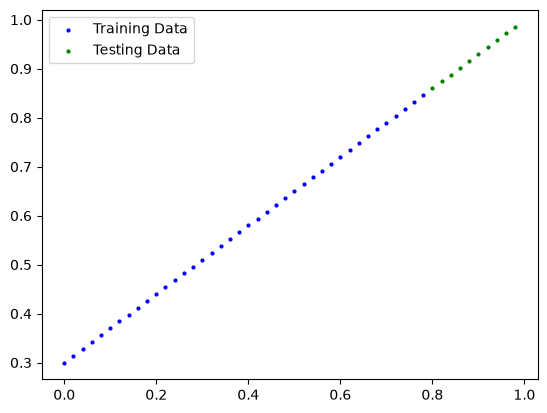

In [15]:
plot_the_graph()

In [16]:
#Class of building the LinearRegression Class -> Almost everything in PyTorch comes from nn.Module
#This tensor is a learnable parameter (nn.parameter) of my neural network. Update it during training using backpropagation and the optimizer
class LinearRegression(nn.Module): #nn.Module -> Parent Class
    def __init__(self):
        super().__init__() #This is used to extract the properties from the Parent cLass nn.Module
        self.weights = nn.Parameter(torch.rand(1)) #Rand For uniform Distribution(+) and Randn for Normal Distribution (- , +)
        self.bias = nn.Parameter(torch.rand(1))
    #This Function is required to define the forward pass of the model. It takes an input tensor and returns an output tensor. The forward method is called when you call the model on an input tensor.
    def forward(self , x : torch.Tensor):
        return self.weights * x + self.bias
        

In [17]:
#Torch.nn - contains all the building blocks for neural networks. It contains layers, loss functions, and optimizers.
#Torch.nn.Parameter - What parameters are learnable parameters of the model. They are updated during training using backpropagation and the optimizer.
#Torch.nn.Module - Base class for all neural network modules. Your models should also subclass this class.
#Torch.optim - contains all the optimization algorithms. It contains optimizers like SGD, Adam, etc.
#def forward - This is where the computation happens. It takes an input tensor and returns an output tensor. The forward method is called when you call the model on an input tensor.


In [18]:
torch.manual_seed(42)
model_0 = LinearRegression()

print(model_0.weights)
print(model_0.bias)

print(list(model_0.parameters())) #Used to see just the Parameters nn.Parameters

Parameter containing:
tensor([0.8823], requires_grad=True)
Parameter containing:
tensor([0.9150], requires_grad=True)
[Parameter containing:
tensor([0.8823], requires_grad=True), Parameter containing:
tensor([0.9150], requires_grad=True)]


In [19]:
model_0.state_dict() #Used to see the parameters

OrderedDict([('weights', tensor([0.8823])), ('bias', tensor([0.9150]))])

In [20]:
X_test , Y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

In [21]:
#torch.inference_mode() -> when making predictions after training is complete. I don't need gradients; I only want predictions.
#Make Predictions with model
# with torch.inference_mode():
#     y_predicts = model_0(X_test)

with torch.no_grad(): #Faster
    y_predicts = model_0(X_test)
y_predicts


tensor([[1.6208],
        [1.6385],
        [1.6561],
        [1.6738],
        [1.6914],
        [1.7090],
        [1.7267],
        [1.7443],
        [1.7620],
        [1.7796]])

In [22]:
Y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

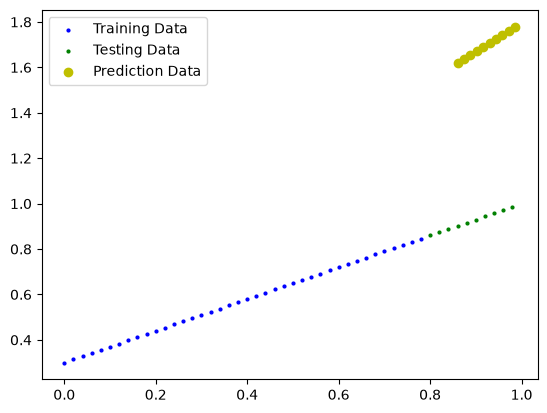

In [23]:
plot_the_graph(predictions_data=y_predicts)

In [24]:
y_predicts_model = model_0(X_test)
y_predicts_model

tensor([[1.6208],
        [1.6385],
        [1.6561],
        [1.6738],
        [1.6914],
        [1.7090],
        [1.7267],
        [1.7443],
        [1.7620],
        [1.7796]], grad_fn=<AddBackward0>)

In [ ]:
#How poor our model is poor on predictions This is done by loss function.LOSS FUNCTION is used to measure how well the model is performing. It takes the predicted values and the true values and returns a single value that represents the error. 
#The goal of training is to minimize this error.

#Loss Function = Loss function is funtion that define how wrong our model is on predictions. This is done by loss function.LOSS FUNCTION is used to measure how well the model is performing.
#Optimizer = Optimizer is used to update the parameters of the model based on the gradients computed during backpropagation. It helps in minimizing the loss function by adjusting the weights and biases of the model.

